Device: cpu
Original train shape: (60000, 28, 28)
Original test shape: (10000, 28, 28)

Training autoencoder with latent dimension = 2
Latent 2 | Epoch 1/8 | Loss: 0.092042
Latent 2 | Epoch 2/8 | Loss: 0.061505
Latent 2 | Epoch 3/8 | Loss: 0.055909
Latent 2 | Epoch 4/8 | Loss: 0.054038
Latent 2 | Epoch 5/8 | Loss: 0.053022
Latent 2 | Epoch 6/8 | Loss: 0.052240
Latent 2 | Epoch 7/8 | Loss: 0.051547
Latent 2 | Epoch 8/8 | Loss: 0.050837
Latent 2 test MSE: 0.050138

Training autoencoder with latent dimension = 8
Latent 8 | Epoch 1/8 | Loss: 0.095060
Latent 8 | Epoch 2/8 | Loss: 0.062078
Latent 8 | Epoch 3/8 | Loss: 0.051516
Latent 8 | Epoch 4/8 | Loss: 0.044605
Latent 8 | Epoch 5/8 | Loss: 0.038356
Latent 8 | Epoch 6/8 | Loss: 0.034412
Latent 8 | Epoch 7/8 | Loss: 0.031783
Latent 8 | Epoch 8/8 | Loss: 0.029677
Latent 8 test MSE: 0.029638

Training autoencoder with latent dimension = 16
Latent 16 | Epoch 1/8 | Loss: 0.093654
Latent 16 | Epoch 2/8 | Loss: 0.062976
Latent 16 | Epoch 3/8 | Lo

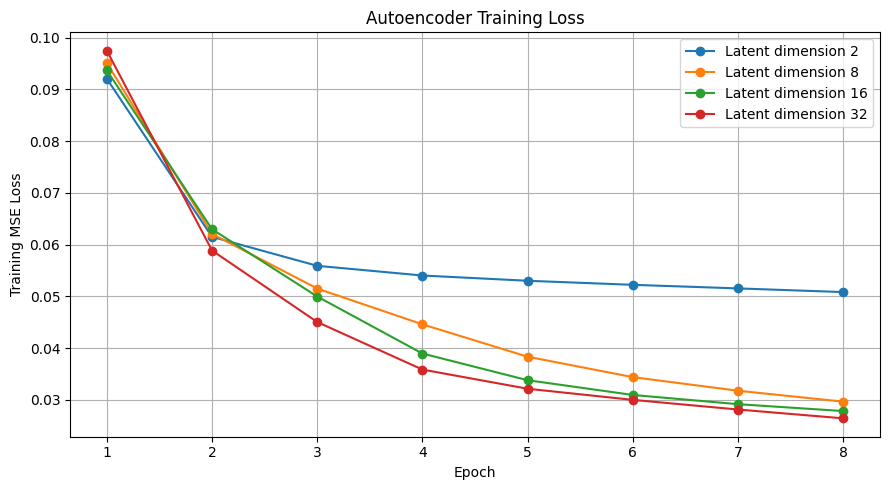

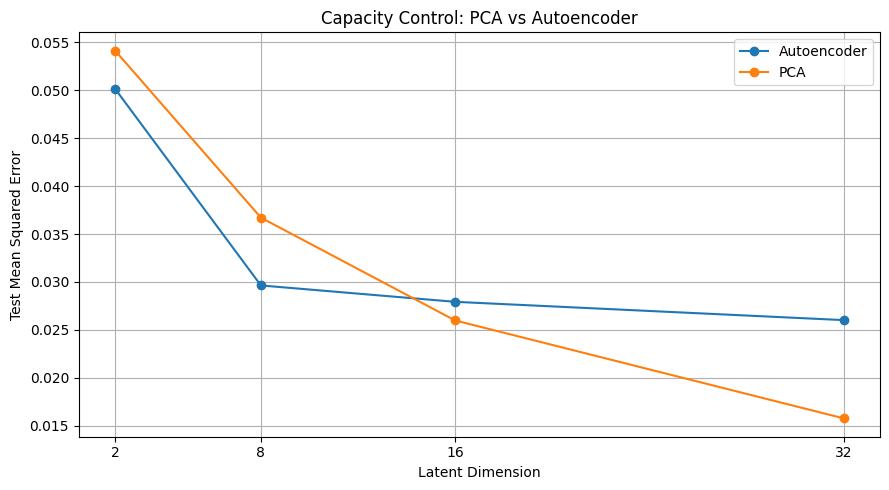

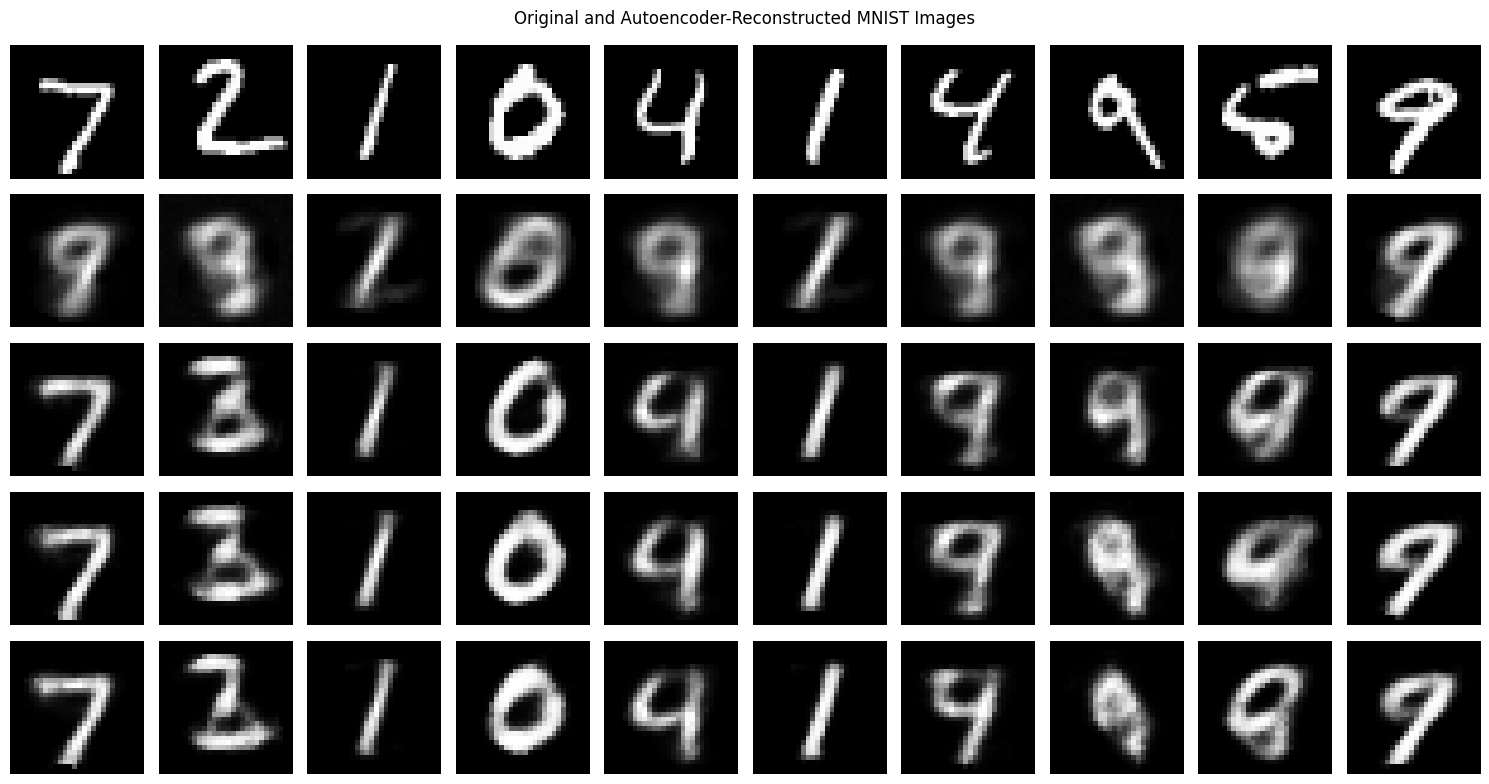

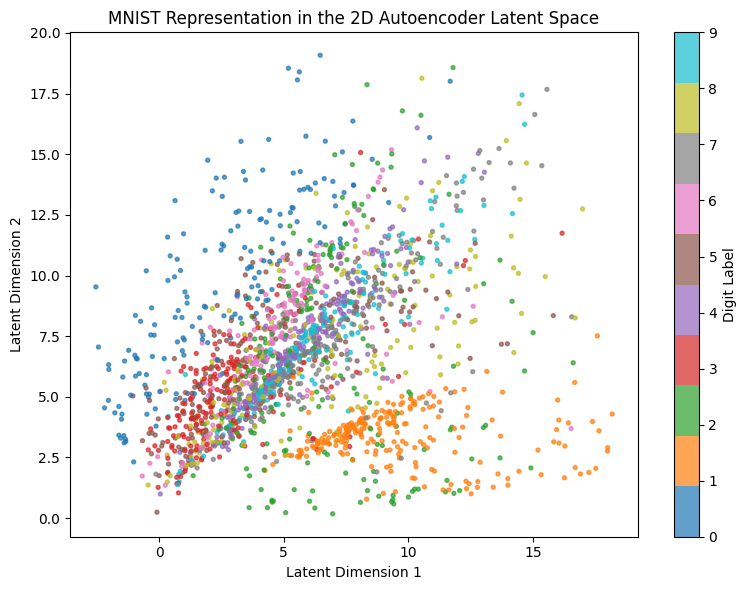


TASK 1.1 COMPLETE
Best tested autoencoder: latent dimension 32, MSE = 0.026021
Best tested PCA: latent dimension 32, MSE = 0.015771

Saved outputs in /kaggle/working/:
- autoencoder_results.csv
- training_loss.png
- pca_vs_autoencoder.png
- reconstruction_comparison.png
- latent_space_2d.png

Analysis guide:
1. A lower test MSE indicates more accurate reconstruction.
2. Larger bottlenecks can preserve more image information.
3. Compare PCA and autoencoder MSE at matching latent dimensions.
4. Inspect reconstructed images to assess visual quality.
5. The 2D latent plot shows how digit classes are represented.
Use the actual printed results in your report.


In [16]:

# TASK 1.1: Undercomplete Autoencoders & Capacity Control
# Dataset: MNIST loaded from Kaggle .npy files
# Models: Autoencoders with latent dimensions 2, 8, 16, 32
# Baseline: PCA

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# -------------------- 1. Reproducibility --------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# -------------------- 2. Load Kaggle MNIST --------------------
DATA_DIR = "/kaggle/input/datasets/hichamachahboun/mnist-handwritten-digits"

X_train = np.load(os.path.join(DATA_DIR, "train_images.npy"))
y_train = np.load(os.path.join(DATA_DIR, "train_labels.npy"))
X_test = np.load(os.path.join(DATA_DIR, "test_images.npy"))
y_test = np.load(os.path.join(DATA_DIR, "test_labels.npy"))

print("Original train shape:", X_train.shape)
print("Original test shape:", X_test.shape)

# Normalize image values to [0, 1]
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

if X_train.max() > 1:
    X_train /= 255.0
if X_test.max() > 1:
    X_test /= 255.0

# Convert images to [number of images, 784]
X_train = X_train.reshape(len(X_train), -1)
X_test = X_test.reshape(len(X_test), -1)

assert X_train.shape[1] == 784, (
    "Expected 28x28 MNIST images. Check the dataset image shape."
)

# Use a subset for PCA and training if necessary
# Increase these limits if your Kaggle GPU/runtime permits.
MAX_TRAIN = min(20000, len(X_train))
MAX_TEST = min(5000, len(X_test))

X_train = X_train[:MAX_TRAIN]
y_train = y_train[:MAX_TRAIN]
X_test = X_test[:MAX_TEST]
y_test = y_test[:MAX_TEST]

train_tensor = torch.tensor(X_train, dtype=torch.float32)
test_tensor = torch.tensor(X_test, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=256,
    shuffle=True
)

# -------------------- 3. Define Autoencoder --------------------
class Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed

# -------------------- 4. Train Different Bottlenecks --------------------
latent_dims = [2, 8, 16, 32]
models = {}
histories = {}
results = []

EPOCHS = 8

for latent_dim in latent_dims:
    print(f"\nTraining autoencoder with latent dimension = {latent_dim}")

    model = Autoencoder(latent_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    train_losses = []

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        total = 0

        for (batch,) in train_loader:
            batch = batch.to(device)

            optimizer.zero_grad()
            reconstructed = model(batch)
            loss = criterion(reconstructed, batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * batch.size(0)
            total += batch.size(0)

        epoch_loss = running_loss / total
        train_losses.append(epoch_loss)

        print(
            f"Latent {latent_dim} | "
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {epoch_loss:.6f}"
        )

    model.eval()
    with torch.no_grad():
        test_recon = []
        test_z = []

        for start in range(0, len(test_tensor), 512):
            batch = test_tensor[start:start + 512].to(device)
            test_recon.append(model(batch).cpu().numpy())
            test_z.append(model.encoder(batch).cpu().numpy())

    X_recon = np.concatenate(test_recon, axis=0)
    Z = np.concatenate(test_z, axis=0)

    mse = mean_squared_error(X_test, X_recon)

    models[latent_dim] = model
    histories[latent_dim] = train_losses

    results.append({
        "Method": "Autoencoder",
        "Latent Dimension": latent_dim,
        "Test MSE": mse
    })

    print(f"Latent {latent_dim} test MSE: {mse:.6f}")

# -------------------- 5. PCA Baseline --------------------
print("\nFitting PCA baseline...")

pca_results = []
pca_models = {}

for latent_dim in latent_dims:
    pca = PCA(n_components=latent_dim, random_state=SEED)
    pca.fit(X_train)

    X_pca_recon = pca.inverse_transform(pca.transform(X_test))
    X_pca_recon = np.clip(X_pca_recon, 0, 1)

    mse = mean_squared_error(X_test, X_pca_recon)

    pca_models[latent_dim] = pca
    pca_results.append({
        "Method": "PCA",
        "Latent Dimension": latent_dim,
        "Test MSE": mse
    })

    print(f"PCA latent {latent_dim} test MSE: {mse:.6f}")

results_df = pd.DataFrame(results + pca_results)
print("\nTest Reconstruction Results:")
print(results_df.to_string(index=False))

results_df.to_csv("/kaggle/working/autoencoder_results.csv", index=False)

# -------------------- 6. Plot Training Loss --------------------
plt.figure(figsize=(9, 5))

for latent_dim in latent_dims:
    plt.plot(
        range(1, EPOCHS + 1),
        histories[latent_dim],
        marker="o",
        label=f"Latent dimension {latent_dim}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/training_loss.png", dpi=150)
plt.show()

# -------------------- 7. Compare Reconstruction Errors --------------------
plt.figure(figsize=(9, 5))

for method in ["Autoencoder", "PCA"]:
    subset = results_df[results_df["Method"] == method]
    plt.plot(
        subset["Latent Dimension"],
        subset["Test MSE"],
        marker="o",
        label=method
    )

plt.xlabel("Latent Dimension")
plt.ylabel("Test Mean Squared Error")
plt.title("Capacity Control: PCA vs Autoencoder")
plt.xticks(latent_dims)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/pca_vs_autoencoder.png", dpi=150)
plt.show()

# -------------------- 8. Display Original vs Reconstructed Images --------------------
n = 10
originals = X_test[:n].reshape(-1, 28, 28)

fig, axes = plt.subplots(
    len(latent_dims) + 1,
    n,
    figsize=(15, 8)
)

for i in range(n):
    axes[0, i].imshow(originals[i], cmap="gray")
    axes[0, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)

for row, latent_dim in enumerate(latent_dims, start=1):
    model = models[latent_dim]
    model.eval()

    with torch.no_grad():
        batch = torch.tensor(
            X_test[:n], dtype=torch.float32, device=device
        )
        reconstructed = model(batch).cpu().numpy()

    reconstructed = reconstructed.reshape(-1, 28, 28)

    for i in range(n):
        axes[row, i].imshow(reconstructed[i], cmap="gray")
        axes[row, i].axis("off")

    axes[row, 0].set_ylabel(f"Latent {latent_dim}", fontsize=10)

plt.suptitle("Original and Autoencoder-Reconstructed MNIST Images")
plt.tight_layout()
plt.savefig("/kaggle/working/reconstruction_comparison.png", dpi=150)
plt.show()

# -------------------- 9. Visualize 2D Latent Space --------------------
model_2d = models[2]
model_2d.eval()

with torch.no_grad():
    Z2 = model_2d.encoder(test_tensor[:2000].to(device)).cpu().numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    c=y_test[:len(Z2)],
    cmap="tab10",
    s=8,
    alpha=0.7
)

plt.colorbar(scatter, label="Digit Label")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("MNIST Representation in the 2D Autoencoder Latent Space")
plt.tight_layout()
plt.savefig("/kaggle/working/latent_space_2d.png", dpi=150)
plt.show()

# -------------------- 10. Final Summary --------------------
print("\n" + "=" * 60)
print("TASK 1.1 COMPLETE")
print("=" * 60)

best_ae = results_df[results_df["Method"] == "Autoencoder"].loc[
    lambda df: df["Test MSE"].idxmin()
]
best_pca = results_df[results_df["Method"] == "PCA"].loc[
    lambda df: df["Test MSE"].idxmin()
]

print(
    f"Best tested autoencoder: latent dimension "
    f"{int(best_ae['Latent Dimension'])}, "
    f"MSE = {best_ae['Test MSE']:.6f}"
)
print(
    f"Best tested PCA: latent dimension "
    f"{int(best_pca['Latent Dimension'])}, "
    f"MSE = {best_pca['Test MSE']:.6f}"
)

print("\nSaved outputs in /kaggle/working/:")
print("- autoencoder_results.csv")
print("- training_loss.png")
print("- pca_vs_autoencoder.png")
print("- reconstruction_comparison.png")
print("- latent_space_2d.png")

print("\nAnalysis guide:")
print("1. A lower test MSE indicates more accurate reconstruction.")
print("2. Larger bottlenecks can preserve more image information.")
print("3. Compare PCA and autoencoder MSE at matching latent dimensions.")
print("4. Inspect reconstructed images to assess visual quality.")
print("5. The 2D latent plot shows how digit classes are represented.")
print("Use the actual printed results in your report.")


In [17]:

import os
import zipfile

output_dir = "/kaggle/working"
zip_path = "/kaggle/working/Task_1_1_Results.zip"

files_to_save = [
    "autoencoder_results.csv",
    "training_loss.png",
    "pca_vs_autoencoder.png",
    "reconstruction_comparison.png",
    "latent_space_2d.png"
]

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in files_to_save:
        filepath = os.path.join(output_dir, filename)
        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

print("\nZIP created:", zip_path)


Added: autoencoder_results.csv
Added: training_loss.png
Added: pca_vs_autoencoder.png
Added: reconstruction_comparison.png
Added: latent_space_2d.png

ZIP created: /kaggle/working/Task_1_1_Results.zip
